# Policy dispatcher run

This notebook runs a config through the dispatcher, writes the Zarr result store under `artifacts/notebook_runs/`, and then reads the generated files back.

## Imports

In [11]:
import json
import sys
import tempfile
from datetime import datetime
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
from dask.distributed import Client, LocalCluster

project_root = Path.cwd()
if not (project_root / "tasks").exists():
    project_root = project_root.parent
if str(project_root) not in sys.path:
    sys.path.insert(0, str(project_root))

from tasks.dispatch.dispatcher import dispatch_from_config
from tasks.policies import load_policy_results

## Start a local Dask cluster

In [12]:
n_workers = 4
threads_per_worker = 1

cluster = LocalCluster(
    n_workers=n_workers,
    threads_per_worker=threads_per_worker,
    processes=False,
    dashboard_address=None,
)
client = Client(cluster)

{
    "scheduler_address": cluster.scheduler_address,
    "dashboard_link": client.dashboard_link,
    "n_workers": len(client.scheduler_info()["workers"]),
    "threads_per_worker": threads_per_worker,
}

{'scheduler_address': 'inproc://134.214.19.74/25787/25',
 'dashboard_link': 'http://134.214.19.74:8787/status',
 'n_workers': 4,
 'threads_per_worker': 1}

## Load the checked-in config and prepare runtime settings

In [13]:
source_config_path = (
    project_root / "configs" / "best_response_policy" / "baseline.dispatch_config.json"
)
source_config = json.loads(source_config_path.read_text(encoding="utf-8"))

started_slug = datetime.now().astimezone().strftime("%Y%m%dT%H%M%S")
run_dir = (
    project_root
    / "artifacts"
    / "notebook_runs"
    / f"best-response-policy-{started_slug}"
)
run_dir.mkdir(parents=True, exist_ok=False)

runtime_config = json.loads(json.dumps(source_config))
runtime_config["scheduler_address"] = cluster.scheduler_address
runtime_config["output_dir"] = str(run_dir)

{
    "source_config_path": str(source_config_path),
    "run_dir": str(run_dir),
    "scheduler_address": runtime_config["scheduler_address"],
    "output_dir": runtime_config["output_dir"],
    "n_agents": runtime_config["simulation"]["n_agents"],
    "write_batch_size": runtime_config["write_batch_size"],
}

{'source_config_path': '/home/hdahmou/Network_creation/configs/best_response_policy/baseline.dispatch_config.json',
 'run_dir': '/home/hdahmou/Network_creation/artifacts/notebook_runs/best-response-policy-20260417T003836',
 'scheduler_address': 'inproc://134.214.19.74/25787/25',
 'output_dir': '/home/hdahmou/Network_creation/artifacts/notebook_runs/best-response-policy-20260417T003836',
 'n_agents': [10, 50],
 'write_batch_size': 64}

## Dispatch the task

In [14]:
with tempfile.NamedTemporaryFile(
    mode="w",
    suffix=".dispatch_config.json",
    encoding="utf-8",
    delete=False,
) as handle:
    json.dump(runtime_config, handle, indent=2)
    handle.write("\n")
    temp_config_path = Path(handle.name)

try:
    dispatch_summary = dispatch_from_config(str(temp_config_path))
finally:
    temp_config_path.unlink(missing_ok=True)

dispatch_summary

INFO Preparing task best-response-policy (tasks.policies.best_response:BestResponsePolicyRun)
INFO Initialized output /home/hdahmou/Network_creation/artifacts/notebook_runs/best-response-policy-20260417T003836/best-response-policy-20260417T003836.zarr
INFO Connected to scheduler inproc://134.214.19.74/25787/25
INFO Run finished for best-response-policy: 32 successes, 0 failures


{'success_count': 32,
 'failure_count': 0,
 'task_name': 'best-response-policy',
 'started_at': '20260417T003836',
 'task_class': 'tasks.policies.best_response:BestResponsePolicyRun',
 'success_rows_written': 32,
 'failure_rows_written': 0,
 'output_zarr': '/home/hdahmou/Network_creation/artifacts/notebook_runs/best-response-policy-20260417T003836/best-response-policy-20260417T003836.zarr',
 'config_copy_path': '/home/hdahmou/Network_creation/artifacts/notebook_runs/best-response-policy-20260417T003836/best-response-policy-20260417T003836.dispatch_config.json'}

## Load formatted policy results

In [15]:
result_store_path = Path(dispatch_summary["output_zarr"])
policy_results = load_policy_results(result_store_path)
input_index = policy_results.metadata["input_index"]
parameter_values = policy_results.inputs["tensors"]["parameters"]
output_tensors = policy_results.outputs["tensors"]
output_labels = policy_results.outputs["labels"]
status_tensors = policy_results.status["tensors"]

{
    "result_store_path": str(policy_results.metadata["result_store_path"]),
    "task_name": policy_results.metadata["task_name"],
    "task_class": policy_results.metadata["task_class"],
    "average_completion_duration_ms": policy_results.metadata[
        "average_completion_duration_ms"
    ],
    "input_index_shape": tuple(input_index.shape),
    "stored_results": int(status_tensors["success"].sum()),
    "stored_failures": int(
        status_tensors["success"].size - status_tensors["success"].sum()
    ),
    "parameters_shape": tuple(parameter_values.shape),
    "output_tensors": {
        name: tuple(values.shape) for name, values in output_tensors.items()
    },
    "status_tensors": {
        name: tuple(values.shape) for name, values in status_tensors.items()
    },
    "n_agents": np.asarray(output_labels["n_agents"]).tolist(),
    "parameter_rows": np.asarray(output_labels["parameter_row"]).tolist(),
    "run_dir_files": sorted(path.name for path in run_dir.iterdir()),
}

{'result_store_path': '/home/hdahmou/Network_creation/artifacts/notebook_runs/best-response-policy-20260417T003836/best-response-policy-20260417T003836.zarr',
 'task_name': 'best-response-policy',
 'task_class': 'tasks.policies.best_response:BestResponsePolicyRun',
 'average_completion_duration_ms': 7447.157421409884,
 'input_index_shape': (2, 16),
 'stored_results': 32,
 'stored_failures': 0,
 'parameters_shape': (2, 16, 6),
 'output_tensors': {'timeseries': (2, 16, 2, 361), 'final': (2, 16, 2)},
 'status_tensors': {'success': (2, 16),
  'error': (2, 16),
  'duration_ms': (2, 16)},
 'n_agents': [10, 50],
 'parameter_rows': [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15],
 'run_dir_files': ['best-response-policy-20260417T003836.dispatch_config.json',
  'best-response-policy-20260417T003836.zarr']}

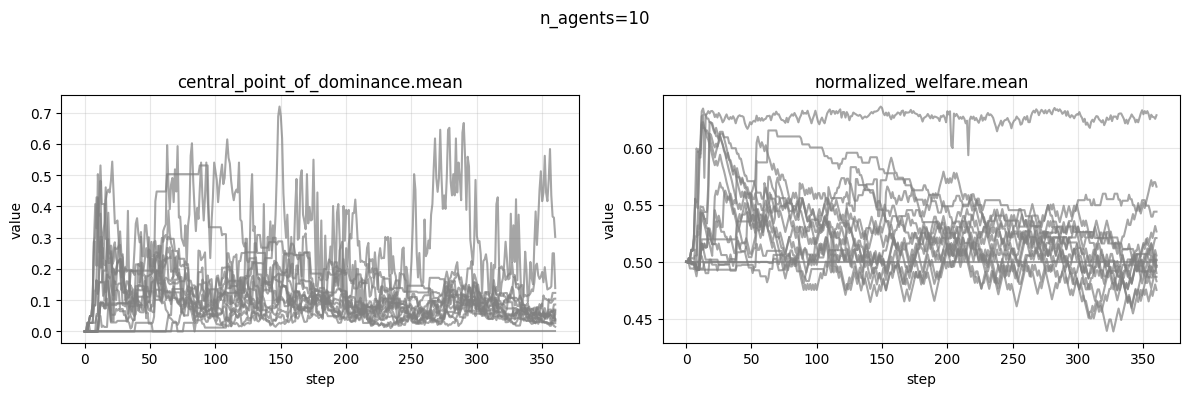

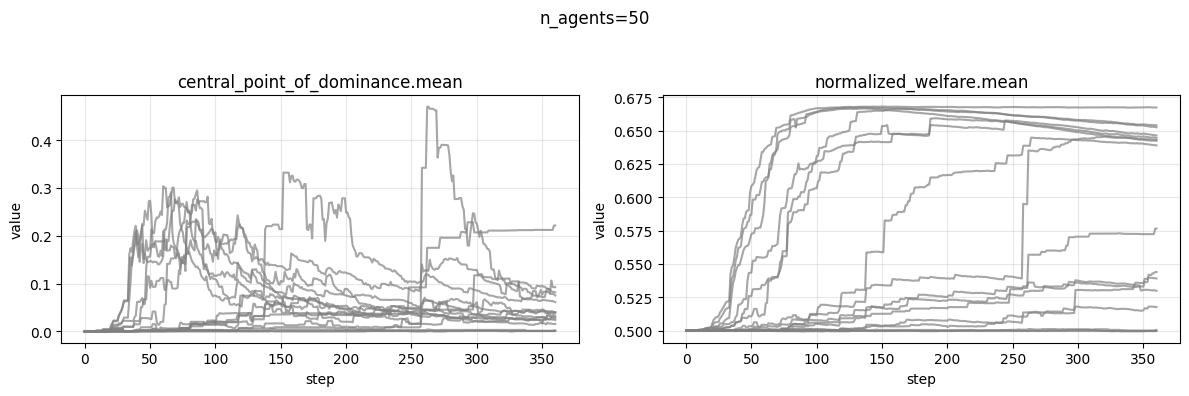

In [ ]:
timeseries = output_tensors["timeseries"]
success = status_tensors["success"]
observables = tuple(output_labels["observable"])
steps = np.asarray(output_labels["step"])
n_agents_values = np.asarray(output_labels["n_agents"])
parameter_rows = np.asarray(output_labels["parameter_row"])

for n_agents_index, n_agents in enumerate(n_agents_values):
    fig, axes = plt.subplots(1, len(observables), figsize=(12, 4), sharex=True)
    axes = np.atleast_1d(axes)
    for observable_index, observable_name in enumerate(observables):
        for parameter_row_index, parameter_row in enumerate(parameter_rows):
            if not success[n_agents_index, parameter_row_index]:
                continue
            axes[observable_index].plot(
                steps,
                timeseries[n_agents_index, parameter_row_index, observable_index],
                alpha=0.7,
                label=f"row={int(parameter_row)}",
                c="gray",
            )
        axes[observable_index].set_title(str(observable_name))
        axes[observable_index].set_xlabel("step")
        axes[observable_index].set_ylabel("value")
        axes[observable_index].grid(alpha=0.3)

    fig.suptitle(f"n_agents={int(n_agents)}")
    handles, labels = axes[0].get_legend_handles_labels()
    plt.tight_layout(rect=(0, 0, 1, 0.94))
    plt.show()

In [ ]:
success = status_tensors["success"]
n_agents_values = np.asarray(output_labels["n_agents"])
parameter_rows = np.asarray(output_labels["parameter_row"])
flat_success = success.reshape(-1)

summary = {
    "n_agents": np.repeat(n_agents_values, len(parameter_rows))[flat_success],
    "parameter_row": np.tile(parameter_rows, len(n_agents_values))[flat_success],
}
flat_parameters = parameter_values.reshape(-1, parameter_values.shape[-1])[flat_success]
flat_final = output_tensors["final"].reshape(-1, output_tensors["final"].shape[-1])[
    flat_success
]

for parameter_index, parameter_name in enumerate(
    policy_results.inputs["labels"]["parameter"]
):
    summary[f"parameter.{parameter_name}"] = flat_parameters[:, parameter_index]

for observable_index, observable_name in enumerate(observables):
    summary[f"{observable_name}.final"] = flat_final[:, observable_index]

summary

## Cleanup

In [ ]:
client.close()
cluster.close()